In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Device selection

In [11]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Auxiliary lattice plot

4 possible layouts


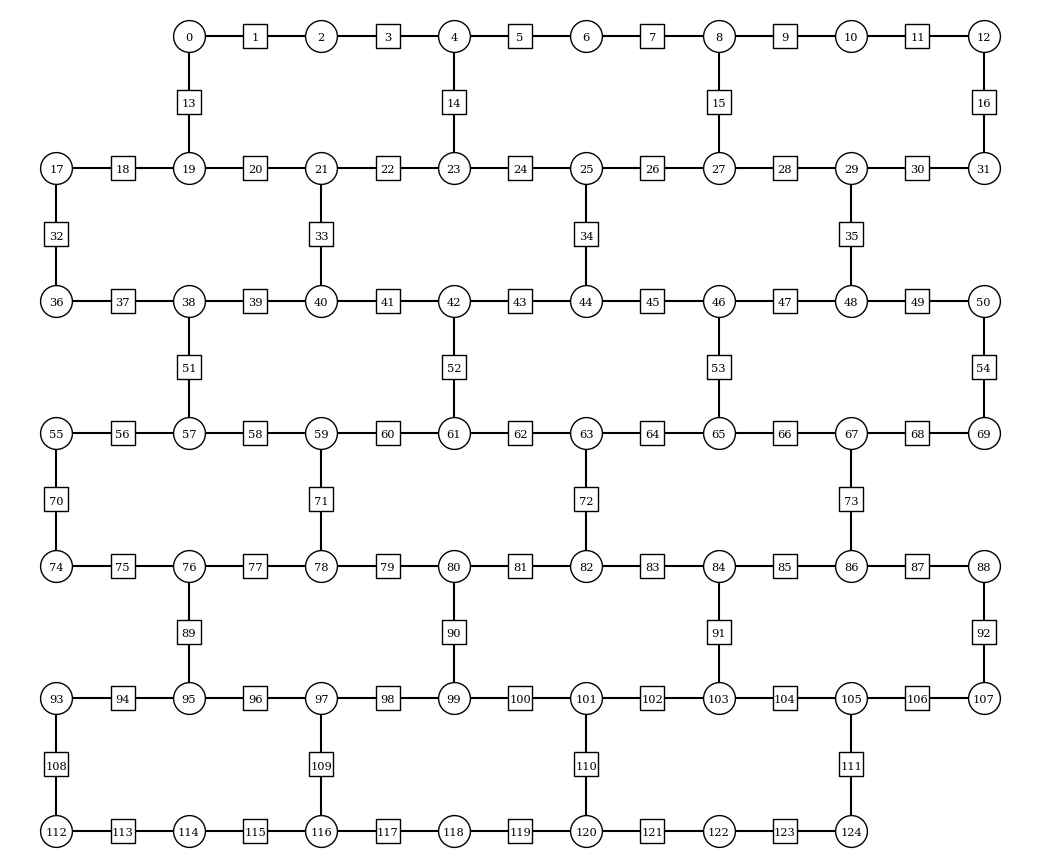

In [12]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 6

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

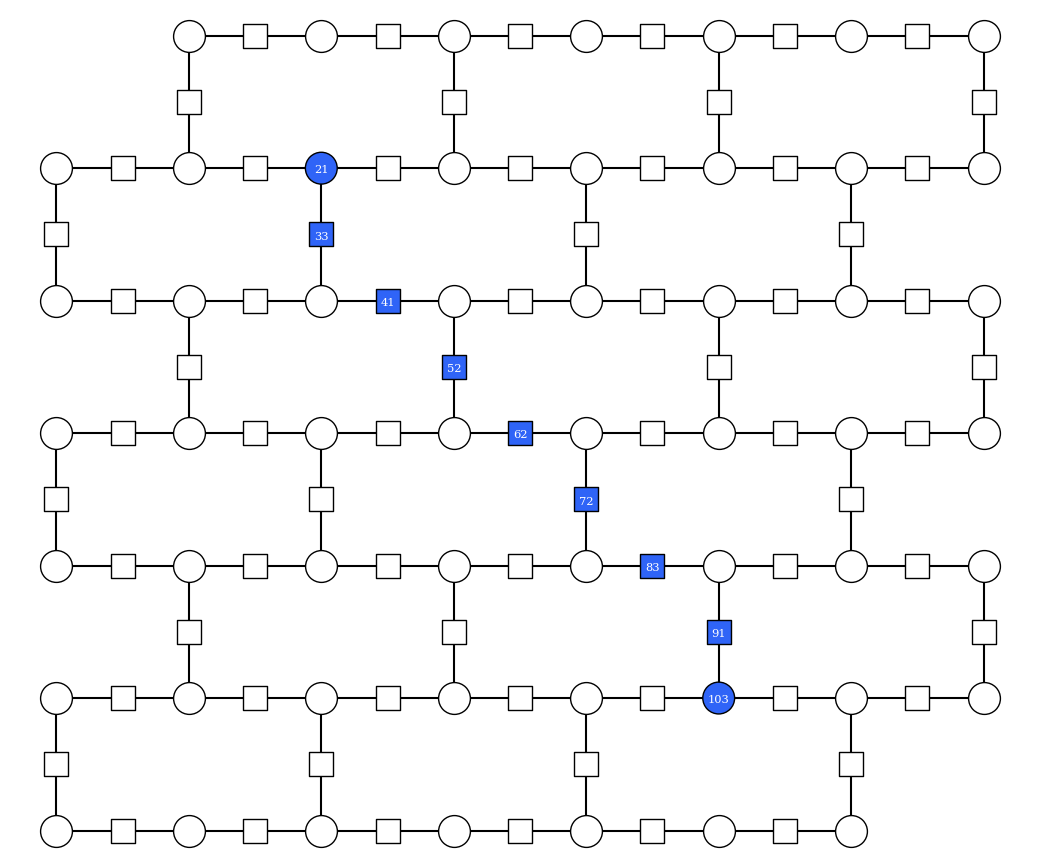

In [13]:
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB

lattice_dims = (plaquette_width, plaquette_height)
J = 2
h = 1.5
lamb = 1
g = 10

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 71, 78]
string = [21, 33, 41, 52, 62, 72, 83, 91, 103]


final_time = 5
dt = 0.15
steps = 40
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 300000

odr = True
flip_threshold = None
all_or_first_layout_qubit = True
forbidden_qubits = []
max_layouts = 5

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string))

# Error guarantees

In [14]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_dt
import numpy as np

lattice = HeavyHexLattice(*lattice_dims)

error_dt = trotter_dt(desired_error, lattice, J, h, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"With provided the hardware error Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*6} 2Qb depth)")

With provided the hardware error Δt should be:
Δt = 0.02559
To correctly reach the desired final time, the number of layers required is:
N = 196 (1176 2Qb depth)


In [15]:
from z2hex.circs import trotter_error

lattice = HeavyHexLattice(*lattice_dims)

settings_error = trotter_error(dt, lattice, J, h, lamb)
sim_max_nlayers = np.ceil(final_time // dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.15000
The error per layer commited in the wrost case is
Ɛ = 2.0129
The number of layers at the final evolution time is
N = 33 (198 2Qb depth)


# Circuit generation & observables

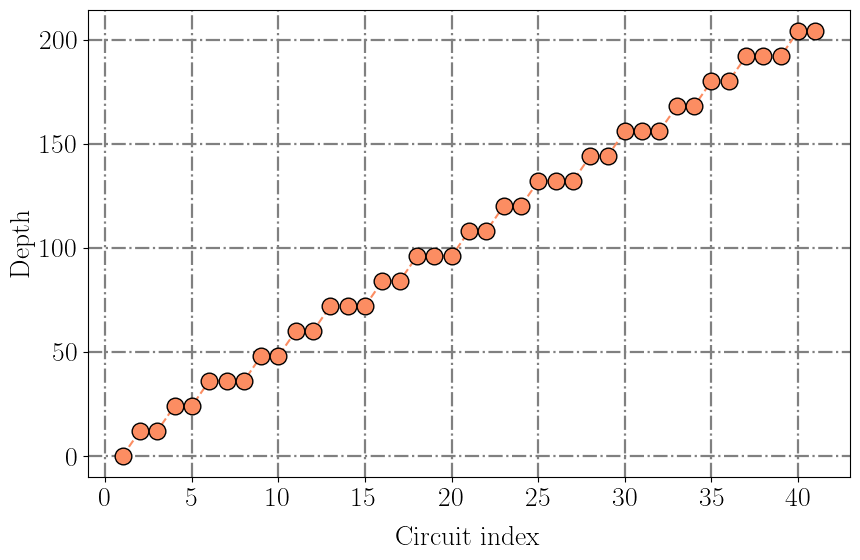

In [16]:
from z2hex.circs import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt, get_layouts
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import numpy as np
import os

optimization_level = 3

lattice = HeavyHexLattice(*lattice_dims)

layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
if layouts.shape[0] > max_layouts:
    rand_idx = np.random.choice(layouts.shape[0], max_layouts, replace=False)
    layouts = layouts[rand_idx, :]
circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.qpy")
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g, layouts, x_basis, True, False)
# if os.path.exists(circuits_filepath):
#     circuits = load_many_layout_circs(circuits_filepath)
# else:
#     circuits = string_quench_simulation_circuits_dt(*circs_args)
    # save_many_layout_circs(circuits_filepath, circuits)
circuits = string_quench_simulation_circuits_dt(*circs_args)
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit} | ({"fractional_gates": True} if fractional_gates else {})
# extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    odr_circuits_filepath = os.path.join(circ_folder_path, f"z2hex_odr_compuncomp_circs_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.qpy")
    odr_func_args = (lattice, J, h, lamb, final_time, dt, steps, backend, g, string, layouts, x_basis)
    if os.path.exists(odr_circuits_filepath):
        odr_circuits = load_many_layout_circs(odr_circuits_filepath)
    else:
        odr_circuits = odr_compuncomp_circuits_dt(*odr_func_args)
        if os.path.isdir(os.path.dirname(circuits_filepath)):
            save_many_layout_circs(odr_circuits_filepath, odr_circuits)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis)

plot_circuit_arr_depth(circuits[0])

# Send jobs to hardware

In [17]:
from utils.postselection import execute_postselected_sampler_batch

if odr:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, odr_circuits, extra_options, job_db)
else:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, job_db=job_db)

execrecord.add_record(J, h, lamb, g, final_time, dt, steps, lattice, all_or_first_layout_qubit, device, shots, string, odr)
print(f"Sent {len(jobs)} jobs")

Sent 328 jobs


# Record tools

## Add separator

In [18]:
# execrecord.add_separator()